# Task-specific temporal Integration Time Window Decoder

Runs a task-specific temporal integration decoder for **all six visual areas** and compares their **integration time windows**. <br>
Of specific interest: : does the window grow larger up the cortical hierarchy, i.e. do higher areas need longer to identify the movie scene?<br>
cortical hierarchy: **VISp → VISl → VISrl → VISal → VISpm → VISam**

For each area and each mouse: cuts the movie into `K` segments (classes), and for a growing time window `Δ` decodes which segment is playing from that area's population spikes (held-out repeats).<br>
Fits a saturating curve → `τ` and `Δ95` (time to 95 % of the asymptotic gain) per (mouse, area), then aggregates across mice and tests the hierarchy trend.

# Imports

In [1]:
# Data handling
import numpy as np
import pandas as pd
# plotting
import matplotlib.pyplot as plt
# managing files
from pathlib import Path
# scipy functionality
from scipy.optimize import curve_fit
from scipy.stats import spearmanr
# decoder models
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_score
# paths
from paths import EXTRACTED_DIR, RESULTS_DIR
# parallelization
from joblib import Parallel, delayed  # for parallelization

## Setup

In [2]:
# Areas listed in order of ascending hierarchy (VISp lowest -> VISam highest)
# order matters for the hierarchy trend test which uses each area's index as its rank
REGIONS = ["VISp", "VISl", "VISrl", "VISal", "VISpm", "VISam"]

# Okabe-Ito Color scheme
REGION_COLORS = {"VISp":"#0072B2","VISl":"#E69F00","VISal":"#009E73",
                 "VISrl":"#D55E00","VISam":"#CC79A7","VISpm":"#56B4E9"}

RANDOM_SEED = 0  # seed for reproducibility

# Analysis parameters
SEG_LEN       = 2.0       # segment length that sets #classes K and the max accumulation window
N_DELTAS      = 14        # number of time windows Δ to test between 1st and SEG_LEN
N_SPLITS      = 5         # number of cross-validation folds
MIN_UNITS     = 10        # minimum amount of units for a session and region
CLF           = "lda"     # classifier id string
SESSION_LIMIT = None      # None = all sessions, small int for a brief test

def make_clf():
    """
    Pipeline so cross_val_score refits cleanly on each fold.
    StandardScaler is fit on only the train fold (no leakage), then LDA/logreg
    """
    if CLF == "lda":       # linear discriminant analysis (default solver, shrinkage="auto" for regularization)
        return make_pipeline(StandardScaler(), LDA(solver="lsqr", shrinkage="auto"))
    if CLF == "logreg":    # logistic regression (linear, regularized)
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
    if CLF == "rf":        # random forest (nonlinear, tree ensemble)
        return make_pipeline(StandardScaler(),
                             RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                                    max_features="sqrt", random_state=RANDOM_SEED))
    if CLF == "svm-rbf":   # kernel SVM (nonlinear via RBF kernel)
        return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=5.0, gamma="scale", random_state=RANDOM_SEED))
    if CLF == "hgb":       # histogram gradient boosting (boosted trees)
        return make_pipeline(StandardScaler(),
                             HistGradientBoostingClassifier(max_depth=3, learning_rate=0.1,
                                                            max_iter=200, random_state=RANDOM_SEED))
    if CLF == "knn":       # k-nearest neighbours (nonlinear, instance-based)
        return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    if CLF == "mlp":       # small neural net
        return make_pipeline(StandardScaler(),
                             MLPClassifier(hidden_layer_sizes=(128,), alpha=1e-2,
                                           max_iter=1000, random_state=RANDOM_SEED))
    raise ValueError(f"unknown CLF {CLF!r}")

plt.rcParams.update({"figure.dpi":110,
                     "axes.spines.top":False,
                     "axes.spines.right":False,
                     "axes.grid":True,
                     "grid.alpha":0.25,
                     "font.size":10})

## Loaders & decoder core functions

In [3]:
def list_sessions(extracted_path=EXTRACTED_DIR):
    """Lists sessions in ascending order"""
    return sorted(Path(extracted_path).glob("session_*.npz"))

def load_session(path):
    """
    Loads a session specified by path, where each session's .npz 
    holds its population tensor + metadata.
    """
    data = np.load(path, allow_pickle=True)
    return dict(counts=data["counts"],                              # [repeat, bin, unit] int16 spike counts
                regions=np.asarray(data["regions"]).astype(str),    # region label per unit (aligned to axis 2)
                bin_size=float(data["bin_size"]),                   # seconds per stored bin (default 10 ms)
                session_id=int(data["session_id"]))

# fix a common K (number of movie segments = number of classes) across all sessions
# because n_bins varies by a few bins across sessions. Pinning K keeps chance identical everywhere.
sessions = list_sessions()

if SESSION_LIMIT:
    sessions = sessions[:SESSION_LIMIT]
bin_size   = load_session(sessions[0])["bin_size"]        # 10 ms
num_bins_perseg = int(round(SEG_LEN / bin_size))          # bins per segment
minb = min(load_session(p)["counts"].shape[1] for p in sessions) # session with the lowest number of bins
K      = int(minb // num_bins_perseg)                     # largest number of segments that fit in every session (esp. the shortest sessiosn)
CHANCE = 1.0 / K                                          # a K-way classifier's chance accuracy

# The Δ grid: accumulation windows from 1st bin up to a full segment, in seconds.
DELTAS = np.unique(np.clip(np.round(np.linspace(bin_size, SEG_LEN, N_DELTAS) / bin_size).astype(int), 1, num_bins_perseg)) * bin_size
print(f"segment={SEG_LEN}s -> {num_bins_perseg} bins | K={K} classes (chance={CHANCE:.3f}) | "
      f"{len(DELTAS)} Δ values {DELTAS[0]*1000:.0f}-{DELTAS[-1]*1000:.0f} ms")

def region_counts(session, region):
    """
    Selects only the specified region's units, 
    and only the first K*nbps bins (whole segments).
    """
    m = session["regions"] == region
    return session["counts"][:, :K*num_bins_perseg, m]                     # [repeat, K*nbps, n_region_units]

def accumulated_features(spike_count_data, n_delta):
    """
    Builds the decoding matrix for one accumulation window of ndelta bins.
    spike_count_data : [repeat, K*nbps, unit]
    Reshapes time points into (segment, within-segment-bin),
    Sums spikes from each segment's onset up to ndelta (window length) bins  
    Returns one feature vector (per unit),  per (repeat, segment)
      data: summed spike counts with one row per repeat/segment, one column per unit
      seg_id: segment ID of each row (target class for prediction by decoder)
      repeat_id: repeat ID for each row, used by cross-validation to hold out entire repeats
    """
    
    repeat_count, _, unit_count = spike_count_data.shape
    spike_counts_reshaped = spike_count_data.reshape(repeat_count, K, num_bins_perseg, unit_count)[:, :, :n_delta, :].sum(2)  # [repeat, segment, unit]
    data = spike_counts_reshaped.reshape(repeat_count*K, unit_count).astype(float)  # rows = (repeat, segment) trials
    seg_id = np.tile(np.arange(K), repeat_count)       # class label = segment id
    repeat_id = np.repeat(np.arange(repeat_count), K)  # group = repeat (for CV)
    return data, seg_id, repeat_id

def decode_curve(spike_count_data):
    """
    Cross-validated segment-decoding accuracy at each Δ in DELTAS.
    GroupKFold holds out whole repeats, so the classifier is always tested on
    repeats it never trained on (no trial leakage between train and test).
    """
    cv = GroupKFold(n_splits=min(N_SPLITS, spike_count_data.shape[0]))  # set up GroupKFold split
    acc_features = []
    for dt in DELTAS:
        n_delta = int(np.clip(round(dt / bin_size), 1, num_bins_perseg)) # bin count for the current time window dt            # window length in bins
        data, seg_id, repeat_id = accumulated_features(spike_count_data, n_delta)
        acc_features.append(cross_val_score(make_clf(), data, seg_id, groups=repeat_id, cv=cv, scoring="accuracy").mean())  # mean CV accuracy at this Δ (parallelism is handled per-session in the Run cell)
    return np.array(acc_features)

def saturate(x, a_0, ainf, tau):
    """
    Defines the saturating exponential: starts near a_0,
    rises to asymptote ainf with time-constant tau.
    Parameters:
      a_0: starting accuracy
      ainf: curve's estimated long-window accuracy
      tau: controls how quickly saturating limit is approached
    """
    
    return ainf - (ainf - a_0) * np.exp(-x / tau)

def fit_window(deltas, accs):
    """
    Fits the saturating curves, uses curve_fit to estimate the 3 parameters 
    from the measured accuracies at the tested window.
    Returns tau and Δ95 = 3*tau (time to 95% of the asymptotic gain).
    Parameters:
      deltas: tested windows
      accs: measured accuracies
    """
    # initial guess for the fitting algorithm
    p_0 = [max(accs[0], CHANCE), max(accs[-1], accs[0] + 1e-3), deltas[-1] / 3]
    try:
        # optimized parameter values form curve_fit
        popt, _ = curve_fit(saturate, deltas, accs, p0=p_0,
                            bounds=([0, 0, 1e-3], [1, 1, deltas[-1]*5]), maxfev=20000)
        # popt[2] is the fitted tau and popt[1] is the fitted ainf
        return dict(tau=popt[2], d_95=3.0*popt[2], ainf=popt[1])
    except Exception:
        return None

segment=2.0s -> 200 bins | K=15 classes (chance=0.067) | 14 Δ values 10-2000 ms


## Run: every region, every mouse
Computes the accuracy curve and fit its window for every (mouse, region) with sufficient units.<br>
Outer loop over sessions (each loaded once), inner loop over regions.<br>
n_deltas can be reduced or the SESSION_LIMIT set for a quick dry run.

In [4]:
# results[region] yields a list of per-mouse dicts {sid, n_units, acc (array over DELTAS), tau, d_95}
results = {region: [] for region in REGIONS}

def process_session(path):
    """
    Decodes every visual region of one session. Each (session, region) decode is
    independent, making parallelization possible via a joblib worker process. Returns
    everything needed to rebuild `results` dictionary and print the per-session
    log back in the main process.
    """
    session = load_session(path)  # each worker loads its own session
    out, decoded, skipped = [], [], []
    # loops over all regions
    for region in REGIONS:
        spike_count_data = region_counts(session, region)  # selects region's units
        n_units   = spike_count_data.shape[2]
        n_repeats = spike_count_data.shape[0]
        
        # skips if too few units in the area, or too few repeats to cross-validate
        if n_units < MIN_UNITS or n_repeats < N_SPLITS:
            reasons = []
            if n_units < MIN_UNITS:   reasons.append(f"{n_units} units < {MIN_UNITS}")
            if n_repeats < N_SPLITS:  reasons.append(f"{n_repeats} repeats < {N_SPLITS}")
            skipped.append(f"{region} ({'; '.join(reasons)})")
            continue

        acc = decode_curve(spike_count_data)  # cross-validated accuracy at each Δ
        fit = fit_window(DELTAS, acc)         # fit the saturating decoding time window
        out.append((region, dict(sid=session["session_id"],
                            n_units=n_units,
                            acc=acc,
                            tau=(fit["tau"] if fit else np.nan),
                            d_95=(fit["d_95"] if fit else np.nan))))
        decoded.append(f"{region}:{n_units}u")

    return session["session_id"], out, decoded, skipped

# Parallelizes the per-session decode (n_jobs=-1 uses all cores)
per_session = Parallel(n_jobs=-1)(delayed(process_session)(p) for p in sessions)

# Reassembles the results dict (joblib preserves submission order) and prints the per-session log
for session_idx, (session_id, out, decoded, skipped) in enumerate(per_session, 1):
    for region, result_dict in out:  # iterates over the successfully decoded regions out
        results[region].append(result_dict)
    status = []
    if decoded:
        status.append("decoded: " + ", ".join(decoded))
    else:
        status.append("skipped: " + ", ".join(skipped))
    print(f"[{session_idx}/{len(sessions)}] session {session_id}  ->  " + " | ".join(status))

# builds compact per-region summary table
rows = []
for region in REGIONS:
    d_95 = np.array([e["d_95"] for e in results[region]], float)
    tau = np.array([e["tau"] for e in results[region]], float)
    d_95 = d_95[np.isfinite(d_95)]
    tau = tau[np.isfinite(tau)]
    
    rows.append(dict(region=region, n_mice=len(results[region]),
                     tau_ms=round(1000*np.nanmedian(tau), 0) if len(tau) else np.nan,
                     d_95_ms=round(1000*np.nanmean(d_95), 0) if len(d_95) else np.nan,
                     sem_ms=round(1000*np.nanstd(d_95)/np.sqrt(max(1,len(d_95))), 0) if len(d_95) else np.nan))

# prints the summary table
summary = pd.DataFrame(rows)
print()
print(summary.to_string(index=False))

[1/32] session 715093703  ->  decoded: VISp:41u, VISl:28u, VISrl:43u, VISpm:30u, VISam:19u
[2/32] session 719161530  ->  decoded: VISp:39u, VISl:29u, VISpm:13u, VISam:23u
[3/32] session 721123822  ->  decoded: VISp:27u, VISl:21u, VISrl:33u, VISal:27u, VISam:18u
[4/32] session 732592105  ->  decoded: VISp:73u, VISl:16u, VISrl:47u, VISal:50u, VISpm:44u
[5/32] session 737581020  ->  decoded: VISp:27u, VISl:10u, VISrl:37u
[6/32] session 739448407  ->  decoded: VISp:10u, VISl:14u, VISrl:43u, VISam:36u
[7/32] session 742951821  ->  decoded: VISp:17u, VISl:30u, VISrl:52u, VISal:26u, VISpm:14u
[8/32] session 743475441  ->  decoded: VISp:33u, VISl:14u, VISrl:33u, VISam:36u
[9/32] session 744228101  ->  decoded: VISp:21u, VISl:13u, VISrl:14u, VISal:22u
[10/32] session 746083955  ->  decoded: VISrl:22u, VISal:19u, VISpm:75u
[11/32] session 750332458  ->  decoded: VISp:42u, VISl:24u, VISrl:23u, VISal:44u, VISpm:13u, VISam:39u
[12/32] session 750749662  ->  decoded: VISp:28u, VISrl:23u, VISal:30u, 

## Comparisons across regions: integration time windows and accuracy vs Δ

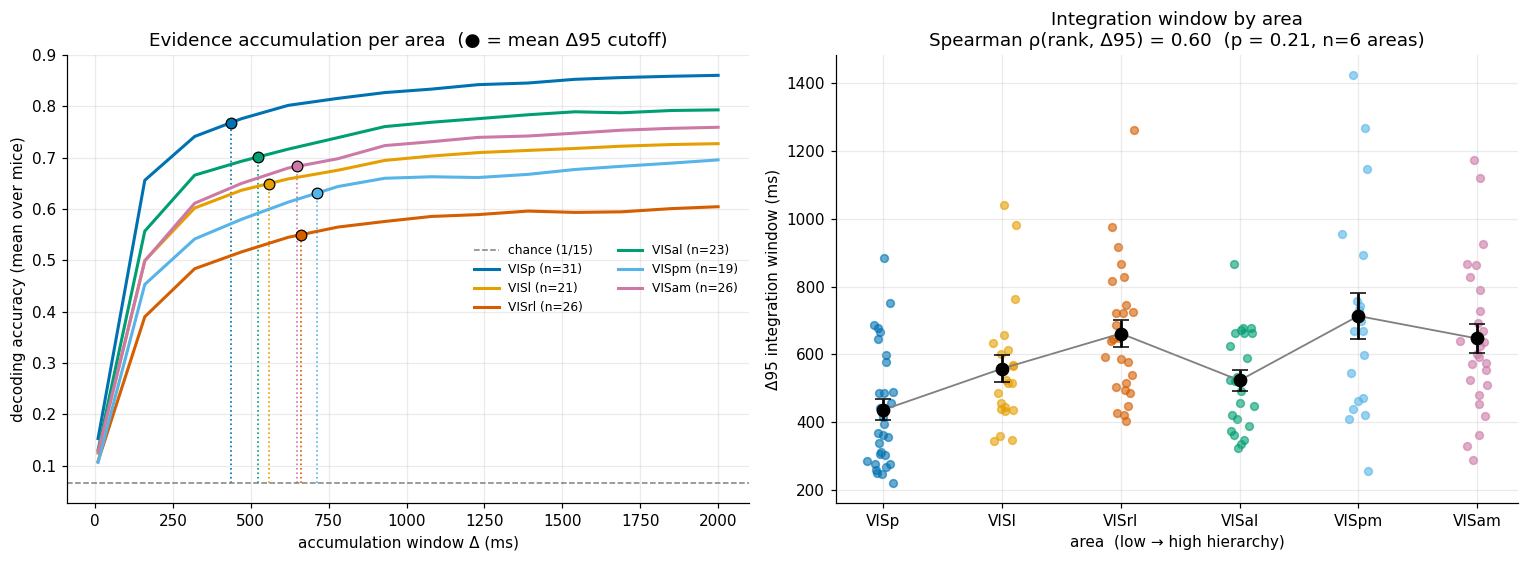

saved figure -> C:\Users\Mariu\Desktop\Scientific_Programming_Project\decoder_results\integration_windows_across_regions_lda.png (+ .svg)
saved windows -> C:\Users\Mariu\Desktop\Scientific_Programming_Project\decoder_results\integration_windows_d_95_ms_lda.csv


,VISp,VISl,VISrl,VISal,VISpm,VISam
session_id,,,,,,
715093703,395.927005,438.242112,585.397770,NaN,419.819042,668.122809
719161530,362.579690,456.496794,NaN,NaN,757.208474,925.374655
721123822,355.652185,523.842982,404.419797,458.027516,NaN,691.272870
732592105,487.269944,1041.695892,817.666031,446.813656,543.848805,NaN
737581020,307.340416,444.487789,421.248217,NaN,NaN,NaN
739448407,576.071961,486.471719,828.876091,NaN,NaN,867.543898
742951821,490.253431,600.151065,746.754499,670.763594,1266.931169,NaN
743475441,751.374282,612.028629,976.489463,NaN,NaN,862.401969
744228101,676.984878,569.186412,505.092194,663.670293,NaN,NaN


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# left panel: mean accuracy-vs-Δ per region (one line per area)
ax = axes[0]
ax.axhline(CHANCE, color="0.5", ls="--", lw=1, label=f"chance (1/{K})")

# iterates over all regions
for region in REGIONS:
    if not results[region]:
        continue
    curve = np.vstack([e["acc"] for e in results[region]]).mean(0)
    ax.plot(DELTAS*1000, curve, color=REGION_COLORS[region], lw=2.0, label=f"{region} (n={len(results[region])})")
    d_95   = np.nanmean([e["d_95"] for e in results[region]]) * 1000  # mean Δ95 (ms)
    acc_cutoff = np.interp(d_95, DELTAS*1000, curve)                  # accuracy at the cutoff
    ax.plot([d_95], [acc_cutoff], "o", color=REGION_COLORS[region], ms=7, mec="black", mew=0.8, zorder=5)
    ax.vlines(d_95, CHANCE, acc_cutoff, color=REGION_COLORS[region], ls=":", lw=1.1, zorder=1)

ax.set_xlabel("accumulation window Δ (ms)")
ax.set_ylabel("decoding accuracy (mean over mice)")
ax.set_title("Evidence accumulation per area  (● = mean Δ95 cutoff)")
ax.legend(frameon=False, ncol=2, fontsize=8)

# right panel: integration window Δ95 by area, ordered along the hierarchy
ax = axes[1]
rng = np.random.default_rng(RANDOM_SEED)
means = []

# iterates over the regions
for i, region in enumerate(REGIONS):
    d_95 = np.array([e["d_95"] for e in results[region]], float) * 1000
    d_95 = d_95[np.isfinite(d_95)]
    if len(d_95) == 0:
        means.append(np.nan)
        continue
    ax.scatter(i + rng.normal(0, 0.06, len(d_95)), d_95, color=REGION_COLORS[region], alpha=0.6, s=26)  # per-mouse
    m, sem = d_95.mean(), d_95.std()/np.sqrt(len(d_95))  # with m=mean and sem=standard error of the mean
    ax.errorbar(i, m, yerr=sem, fmt="o", color="black", ms=8, capsize=5, lw=1.8, zorder=5)  # mean±SEM
    means.append(m)

ax.plot(range(len(REGIONS)), means, color="0.5", lw=1.2, zorder=1)  # trend line
ax.set_xticks(range(len(REGIONS)))
ax.set_xticklabels(REGIONS)
ax.set_xlabel("area  (low → high hierarchy)")
ax.set_ylabel("Δ95 integration window (ms)")

# hierarchy test: does the window increase with hierarchy rank? (Spearman over the 6 area means)
valid = [(i, m) for i, m in enumerate(means) if np.isfinite(m)]
if len(valid) >= 3:
    rho, pval = spearmanr([v[0] for v in valid], [v[1] for v in valid])
    ax.set_title(f"Integration window by area\nSpearman ρ(rank, Δ95) = {rho:.2f}  (p = {pval:.2f}, n={len(valid)} areas)")
else:
    ax.set_title("Integration window by area")

plt.tight_layout()
plt.show()

# Saves the figure
fig_path = RESULTS_DIR / f"integration_windows_across_regions_{CLF}.png"
fig.savefig(fig_path, dpi=200, bbox_inches="tight")
fig.savefig(fig_path.with_suffix(".svg"), bbox_inches="tight")
print("saved figure ->", fig_path, "(+ .svg)")

# Saves data table of the Δ95 integration windows (in ms) for each session and area
session_ids = sorted({e["sid"] for r in REGIONS for e in results[r]})  # extracts all session IDs from the results
d_95_ms = pd.DataFrame(index=session_ids, columns=REGIONS, dtype=float)  # makes dataframe with session IDs as rows and regions as columns
d_95_ms.index.name = "session_id"

# iterates over all regions
for region in REGIONS:                       # columns stay in hierarchical order (VISp → VISam)
    for result in results[region]:
        d_95_ms.loc[result["sid"], region] = result["d_95"] * 1000.0   # conversion from seconds to ms

csv_path = RESULTS_DIR / f"integration_windows_d_95_ms_{CLF}.csv"  # creates save path for the CSV file
d_95_ms.to_csv(csv_path)  # actual saving
print("saved windows ->", csv_path)
d_95_ms   # displays the table

## Integration time windows further visualization

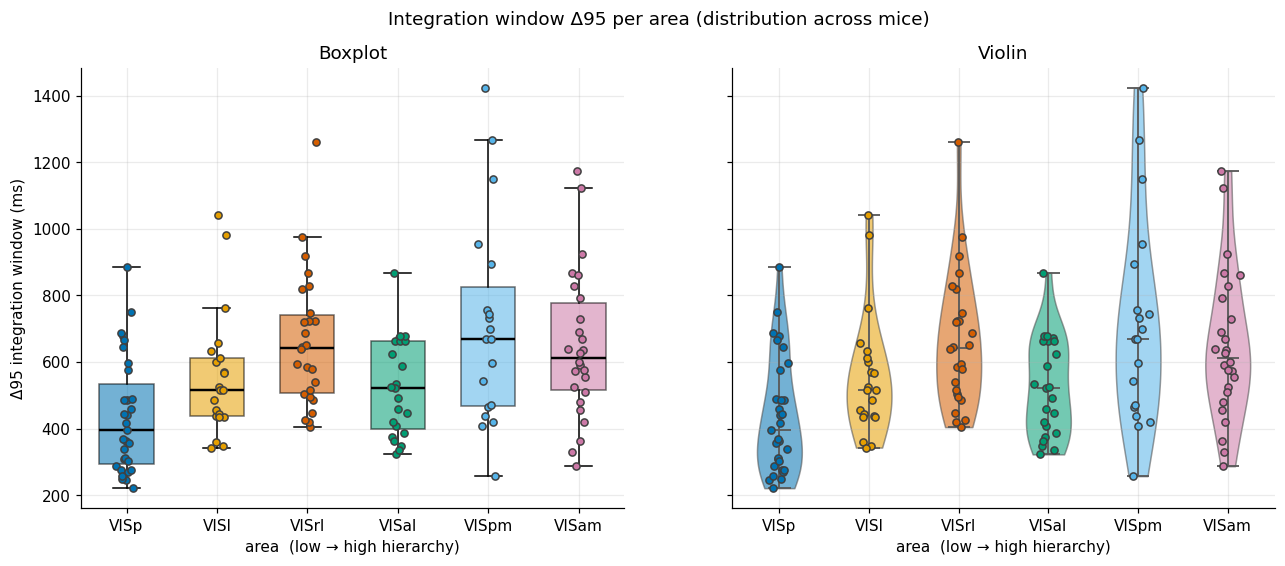

In [6]:
# extracts the per-area Δ95 values and converts them to milliseconds
d_95_by = {region: np.array([result["d_95"] for result in results[region]], float) * 1000 for region in REGIONS}
# keeps only finite values
d_95_by = {region: d95_val[np.isfinite(d95_val)] for region, d95_val in d_95_by.items()}
order  = [region for region in REGIONS if len(d_95_by[region]) > 0]  # keeps hierarchy order
data   = [d_95_by[region] for region in order]  # a list of the ordered Δ95 arrays, one per region
colors   = [REGION_COLORS[region] for region in order]  # the corresponding colors for each region
rng    = np.random.default_rng(RANDOM_SEED)  #seeded random generator with the predefined seed for the jitter of overlapping points

# sets up the figure with two subplots: left for boxplots, right for violin plots
fig2, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)

# left panel: boxplots
boxplots = axes[0].boxplot(data, patch_artist=True, widths=0.6, showfliers=False)  # patch_artist=True makes the boxes fillable shapes (for coloring)

# Sets the style for the boxplots (colors each boxplot)
for patch, color in zip(boxplots["boxes"], colors): 
    patch.set_facecolor(color)
    patch.set_alpha(0.55)
# Sets the style for the median lines 
for median in boxplots["medians"]:  
    median.set_color("black")
    median.set_linewidth(1.6)
# Plots the per-mouse d95 points on each box
for i, (d, color) in enumerate(zip(data, colors), 1):          # overlay per-mouse points
    axes[0].scatter(i + rng.normal(0, 0.05, len(d)), d, color=color, edgecolor="0.25", s=22, zorder=3)

# Sets the x-ticks and labels for the boxplot
axes[0].set_xticks(range(1, len(order)+1))
axes[0].set_xticklabels(order)
axes[0].set_ylabel("Δ95 integration window (ms)")
axes[0].set_xlabel("area  (low → high hierarchy)")
axes[0].set_title("Boxplot")

# right panel: violin plots
violinplots = axes[1].violinplot(data, showmedians=True, showextrema=True)
# Sets the general style for the violin plots
for b, color in zip(violinplots["bodies"], colors): 
    b.set_facecolor(color)
    b.set_alpha(0.55)
    b.set_edgecolor("0.3")
# Sets the style for the violin plot markers
for key in ("cmedians", "cmins", "cmaxes", "cbars"):
    if key in violinplots: 
        violinplots[key].set_color("0.35")
        violinplots[key].set_linewidth(1.2)
    # Plots the per-mouse d95 points on each violin
for i, (d, color) in enumerate(zip(data, colors), 1):
    axes[1].scatter(i + rng.normal(0, 0.05, len(d)), d, color=color, edgecolor="0.25", s=22, zorder=3)

# Sets the x-ticks and labels for the violin plot
axes[1].set_xticks(range(1, len(order)+1))
axes[1].set_xticklabels(order)
axes[1].set_xlabel("area  (low → high hierarchy)")
axes[1].set_title("Violin")

# Saving the figures
fig2.suptitle("Integration window Δ95 per area (distribution across mice)")
# saves as .png-file
fig2.savefig(RESULTS_DIR / f"integration_windows_box_violin_{CLF}.png", dpi=200, bbox_inches="tight")
# saves as .svg-file
fig2.savefig(RESULTS_DIR / f"integration_windows_box_violin_{CLF}.svg", bbox_inches="tight")

plt.show()

## Notes / caveats

- **Spearman Rank correlation:** A positive Spearman ρ between area rank and Δ95 supports the hypothesis that "higher areas integrate longer." With only 6 areas the test has little power, so ρ should be read as a trend and not as proof. The per-area mean ± SEM (mice) is to be preferred as a measure over the single Spearman correlation
- **Aggregation over mice:** Each (mouse, area) gives one τ/Δ95, meaning areas are compared on those per-mouse values. Units are never combined (pooled) across animals
- **Area-specific sampling:** Areas are sampled by different subsets of mice and unit counts (see coverage heatmap); a shorter/longer window in a sparsely sampled area is less trustworthy
- **Knobs:** `SEG_LEN` sets both #classes and max Δ; `CLF` specifies the classifier; both affect absolute windows but the *ordering across areas* is largely stable across classifiers